# Stereo calibration and disparity

We find checkerboard corners as in Exercise 1, calibrate the two cameras, and rectify the images so corresponding points lie on the same row. This is the horizontal epipolar geometry from Exercise 2. Then we match the rectified images to measure disparity in pixels.

In [5]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

project_dir = Path(".")
if not (project_dir / "0_calib").is_dir():
    project_dir = Path("finalProject")

calibration_dir = project_dir / "0_calib"

def paired_names(folder):
    left_names = {path.name for path in (folder / "left").glob("*.png")}
    right_names = {path.name for path in (folder / "right").glob("*.png")}
    return sorted(left_names & right_names)

def read_pair(folder, name):
    left = cv2.imread(str(folder / "left" / name))
    right = cv2.imread(str(folder / "right" / name))
    return left, right

calibration_names = paired_names(calibration_dir)
assert calibration_names, "Open the notebook from the finalProject folder with 0_calib inside it."

## 1. Find matching checkerboard corners

The board has 7 × 5 inner corners. Enter the measured side length of one square in metres if you need metric depth later. With `square_size = 1.0`, the baseline and any reconstructed distances are in checkerboard-square units.

In [6]:
cols, rows = 7, 5
pattern_size = (cols, rows)
square_size = 1.0  # One checkerboard square

objp = np.zeros((cols * rows, 3), np.float32)
objp[:, :2] = np.mgrid[:cols, :rows].T.reshape(-1, 2) * square_size

objpoints = []
imgpoints_left = []
imgpoints_right = []
reversed_pairs = []
# This detector already returns subpixel corner positions.
corner_flags = cv2.CALIB_CB_EXHAUSTIVE | cv2.CALIB_CB_ACCURACY

for name in calibration_names:
    left, right = read_pair(calibration_dir, name)
    gray_left = cv2.cvtColor(left, cv2.COLOR_BGR2GRAY)
    gray_right = cv2.cvtColor(right, cv2.COLOR_BGR2GRAY)
    found_left, corners_left = cv2.findChessboardCornersSB(gray_left, pattern_size, flags=corner_flags)
    found_right, corners_right = cv2.findChessboardCornersSB(gray_right, pattern_size, flags=corner_flags)
    if not (found_left and found_right):
        continue

    corners_left = corners_left.reshape(-1, 1, 2)
    corners_right = corners_right.reshape(-1, 1, 2)
    # A symmetric board can be detected starting from opposite ends.
    left_direction = corners_left[cols - 1, 0] - corners_left[0, 0]
    right_direction = corners_right[cols - 1, 0] - corners_right[0, 0]
    if np.dot(left_direction, right_direction) < 0:
        corners_right = corners_right[::-1].copy()
        reversed_pairs.append(name)

    objpoints.append(objp)
    imgpoints_left.append(corners_left)
    imgpoints_right.append(corners_right)

assert len(objpoints) >= 3, "Too few stereo pairs with checkerboard corners."
image_size = gray_left.shape[::-1]
print(f"Usable stereo pairs: {len(objpoints)}/{len(calibration_names)}")
print(f"Right-side corner order reversed in {len(reversed_pairs)} pairs.")

Usable stereo pairs: 34/37
Right-side corner order reversed in 7 pairs.


## 2. Calibrate and rectify

Estimate the intrinsics of each camera as in Exercise 1, then hold them fixed while estimating the relative rotation `R` and translation `T`. After rectification, the vertical difference between matching corners should be close to zero.

In [7]:
rms_left, mtx_left, dist_left, _, _ = cv2.calibrateCamera(
    objpoints, imgpoints_left, image_size, None, None
)
rms_right, mtx_right, dist_right, _, _ = cv2.calibrateCamera(
    objpoints, imgpoints_right, image_size, None, None
)
rms_stereo, mtx_left, dist_left, mtx_right, dist_right, R, T, _, _ = cv2.stereoCalibrate(
    objpoints, imgpoints_left, imgpoints_right,
    mtx_left, dist_left, mtx_right, dist_right, image_size,
    flags=cv2.CALIB_FIX_INTRINSIC,
)

R1, R2, P1, P2, Q, _, _ = cv2.stereoRectify(
    mtx_left, dist_left, mtx_right, dist_right, image_size, R, T,
    flags=cv2.CALIB_ZERO_DISPARITY, alpha=0,
)

rectified_corners_left = cv2.undistortPoints(
    np.concatenate(imgpoints_left), mtx_left, dist_left, R=R1, P=P1
).reshape(-1, 2)
rectified_corners_right = cv2.undistortPoints(
    np.concatenate(imgpoints_right), mtx_right, dist_right, R=R2, P=P2
).reshape(-1, 2)
row_error = np.abs(rectified_corners_left[:, 1] - rectified_corners_right[:, 1])

print(f"Reprojection RMS: left {rms_left:.2f}, right {rms_right:.2f}, stereo {rms_stereo:.2f} px")
print(f"Rectified row difference: median {np.median(row_error):.2f} px, "
      f"95th percentile {np.percentile(row_error, 95):.2f} px")

np.savez(
    calibration_dir / "stereo_calibration.npz",
    mtx_left=mtx_left, dist_left=dist_left,
    mtx_right=mtx_right, dist_right=dist_right,
    R=R, T=T, R1=R1, R2=R2, P1=P1, P2=P2, Q=Q,
    image_size=image_size, square_size=square_size,
)

Reprojection RMS: left 0.14, right 0.13, stereo 0.32 px
Rectified row difference: median 0.28 px, 95th percentile 0.82 px


In [8]:
map_left_x, map_left_y = cv2.initUndistortRectifyMap(
    mtx_left, dist_left, R1, P1, image_size, cv2.CV_32FC1
)
map_right_x, map_right_y = cv2.initUndistortRectifyMap(
    mtx_right, dist_right, R2, P2, image_size, cv2.CV_32FC1
)

def rectify_pair(left, right):
    # Keep the full image so the pixel coordinates still match P1, P2 and Q.
    rectified_left = cv2.remap(left, map_left_x, map_left_y, cv2.INTER_LINEAR)
    rectified_right = cv2.remap(right, map_right_x, map_right_y, cv2.INTER_LINEAR)
    return rectified_left, rectified_right

## 3. Check a rectified pair

The calibration pair below lets you check the geometry using the supplied images. To use, change pair name to another picture if ou want. 

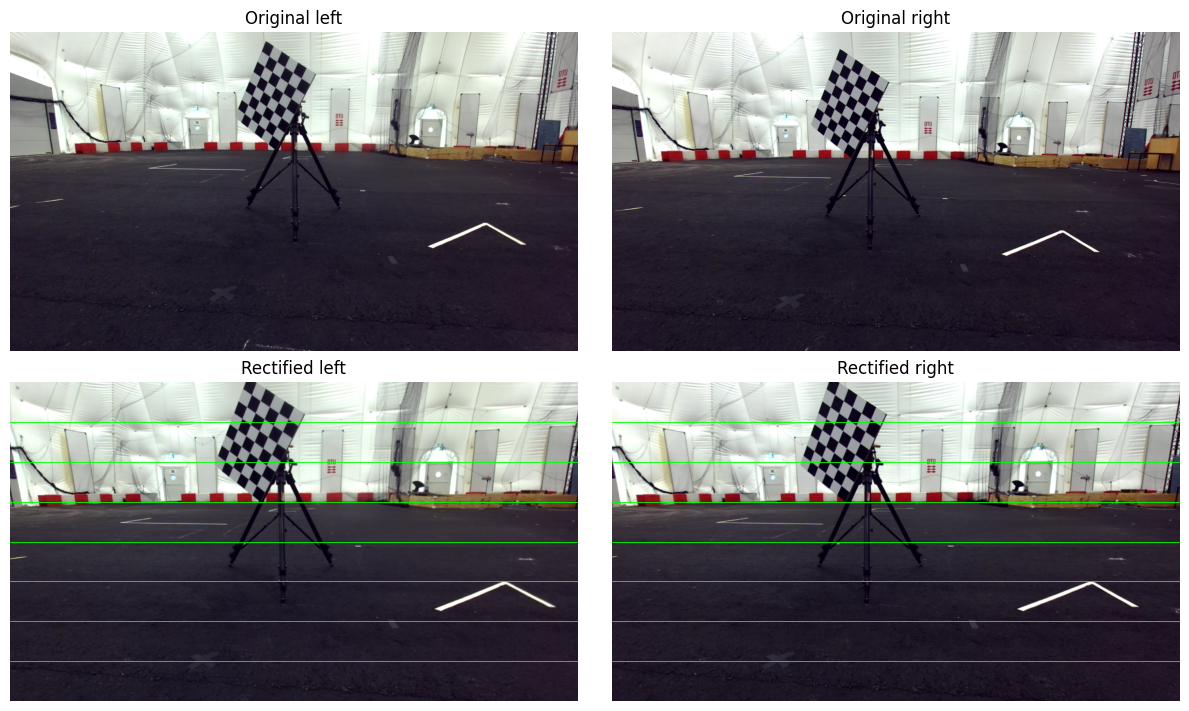

In [9]:
sequence_dir = calibration_dir
pair_name = "011.png"

left, right = read_pair(sequence_dir, pair_name)
assert left is not None and right is not None, f"Missing left or right image for {pair_name}."
assert left.shape[:2] == right.shape[:2] == image_size[::-1], "Use the calibration image resolution."

rectified_left, rectified_right = rectify_pair(left, right)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, img, title in zip(
    axes.flat, (left, right, rectified_left, rectified_right),
    ("Original left", "Original right", "Rectified left", "Rectified right"),
):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

for ax in axes[1]:
    for row in range(90, image_size[1], 90):
        ax.axhline(row, color="lime", linewidth=0.6)
plt.show()

## 4. Compute disparity

StereoSGBM searches along the rows of the rectified images. Disparity is the horizontal shift `x_left - x_right`. Brighter colours indicate a larger shift. Black pixels have no valid match, which can happen at image edges, in areas with little texture, or where one camera cannot see the same point.

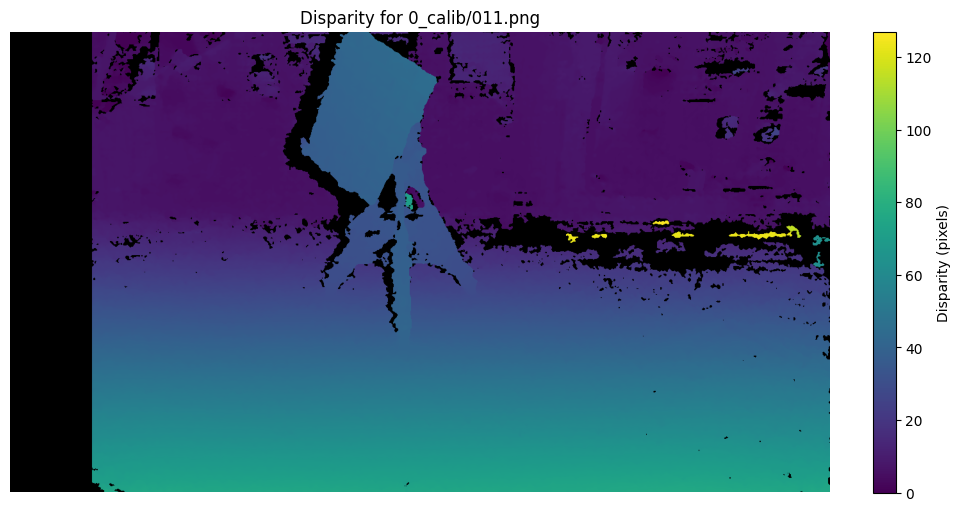

In [10]:
gray_left = cv2.cvtColor(rectified_left, cv2.COLOR_BGR2GRAY)
gray_right = cv2.cvtColor(rectified_right, cv2.COLOR_BGR2GRAY)

min_disparity = 0
num_disparities = 128  # OpenCV requires a multiple of 16
block_size = 5
stereo = cv2.StereoSGBM_create(
    minDisparity=min_disparity,
    numDisparities=num_disparities,
    blockSize=block_size,
    P1=8 * block_size**2,
    P2=32 * block_size**2,
    disp12MaxDiff=1,
    uniquenessRatio=10,
    speckleWindowSize=100,
    speckleRange=2,
)
# SGBM returns disparity in sixteenths of a pixel.
disparity = stereo.compute(gray_left, gray_right).astype(np.float32) / 16
disparity[disparity < min_disparity] = np.nan

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
cmap = plt.get_cmap("viridis").with_extremes(bad="black")
shown = ax.imshow(disparity, cmap=cmap, vmin=min_disparity,
                  vmax=min_disparity + num_disparities - 1)
ax.set_title(f"Disparity for {sequence_dir.name}/{pair_name}")
ax.axis("off")
fig.colorbar(shown, ax=ax, label="Disparity (pixels)")
plt.show()

## 5. Save the rectified pairs

This cell writes the selected folder's rectified pairs to its `rectified/left` and `rectified/right` subfolders. It refreshes the corresponding files if they already exist.

In [11]:
rectified_dir = sequence_dir / "rectified"
(rectified_dir / "left").mkdir(parents=True, exist_ok=True)
(rectified_dir / "right").mkdir(parents=True, exist_ok=True)

for name in paired_names(sequence_dir):
    left, right = read_pair(sequence_dir, name)
    left, right = rectify_pair(left, right)
    cv2.imwrite(str(rectified_dir / "left" / name), left)
    cv2.imwrite(str(rectified_dir / "right" / name), right)